# DeepFER — Phase 3: Deep Learning Model Development

**Environment:** Google Colab  
**Dataset:** Phase 2 processed dataset (48×48 grayscale PNG)  
**Models:** Custom CNN and MobileNetV2 transfer learning  
**Classes:** angry, disgust, fear, happy, neutral, sad, surprise

## Learning objectives
1. Load and verify the leakage-safe train/validation/test folders.
2. Build a reproducible TensorFlow input pipeline.
3. Train a custom CNN with class weighting.
4. Train a transfer-learning model using ImageNet MobileNetV2.
5. Compare validation results and select a model without using the test set.
6. Evaluate the selected model once on the held-out test set.
7. Export the model, class names, metrics and plots for Phase 4 deployment.

**Responsible-use note:** This model estimates visible facial-expression categories in images. It cannot reliably determine a person's actual internal emotional state, intentions, personality or mental health. Use it only as an experimental image-classification project, not for consequential decisions about people.

## 0. Colab setup

Open a new Google Colab notebook, select **Runtime → Change runtime type → T4 GPU** (if available), then run the cells from top to bottom.

Upload `DeepFER_processed_dataset.zip` from Phase 2 when prompted. Keep the Phase 2 test folder untouched during model development.

In [ ]:
import os, json, zipfile, random, shutil, pathlib, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 1. Upload and extract the processed dataset

The ZIP should contain `train/`, `validation/` and `test/`, each with seven class folders. If you have already extracted it into `/content/DeepFER_processed_dataset`, you can skip the upload cell and set `DATA_DIR` accordingly.

In [ ]:
from google.colab import files

uploaded = files.upload()  # Select DeepFER_processed_dataset.zip
zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if zip_name is None:
    raise ValueError("Please upload DeepFER_processed_dataset.zip")

EXTRACT_DIR = "/content/deepfer_data"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(EXTRACT_DIR)

DATA_DIR = EXTRACT_DIR
print("Extracted to:", DATA_DIR)
print("Top-level folders:", os.listdir(DATA_DIR))

Saving DeepFER_processed_dataset.zip to DeepFER_processed_dataset.zip
Extracted to: /content/deepfer_data
Top-level folders: ['validation', 'test', 'train']


### 1.1 Locate the dataset root and validate its structure

This handles ZIP files that either contain the three split folders directly or place them inside one additional parent directory.

In [ ]:
def find_dataset_root(start_dir):
    for root, dirs, files_ in os.walk(start_dir):
        if all(split in dirs for split in ["train", "validation", "test"]):
            return root
    raise FileNotFoundError("Could not find train/validation/test folders.")

DATA_DIR = find_dataset_root(DATA_DIR)
EXPECTED_CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

for split in ["train", "validation", "test"]:
    split_path = os.path.join(DATA_DIR, split)
    found = sorted([d for d in os.listdir(split_path)
                    if os.path.isdir(os.path.join(split_path, d))])
    print(split, "classes:", found)
    if found != EXPECTED_CLASSES:
        raise ValueError(f"Unexpected classes in {split}: {found}")

print("Dataset structure validated.")

train classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
validation classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
test classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Dataset structure validated.


## 2. Load the datasets

We load grayscale images at their original 48×48 resolution for the custom CNN. The labels are inferred from folder names; TensorFlow sorts class names alphabetically, matching `EXPECTED_CLASSES`.

We use `shuffle=True` only for training. Validation and test datasets remain in deterministic order for evaluation.

In [ ]:
IMG_SIZE = (48, 48)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    labels="inferred", label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="grayscale",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "validation"),
    labels="inferred", label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="grayscale",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    labels="inferred", label_mode="int",
    class_names=EXPECTED_CLASSES,
    color_mode="grayscale",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class order:", train_ds.class_names)

Found 27181 files belonging to 7 classes.
Found 3398 files belonging to 7 classes.
Found 3398 files belonging to 7 classes.
Class order: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### 2.1 Inspect sample images

Check that the images and labels look correct before training.

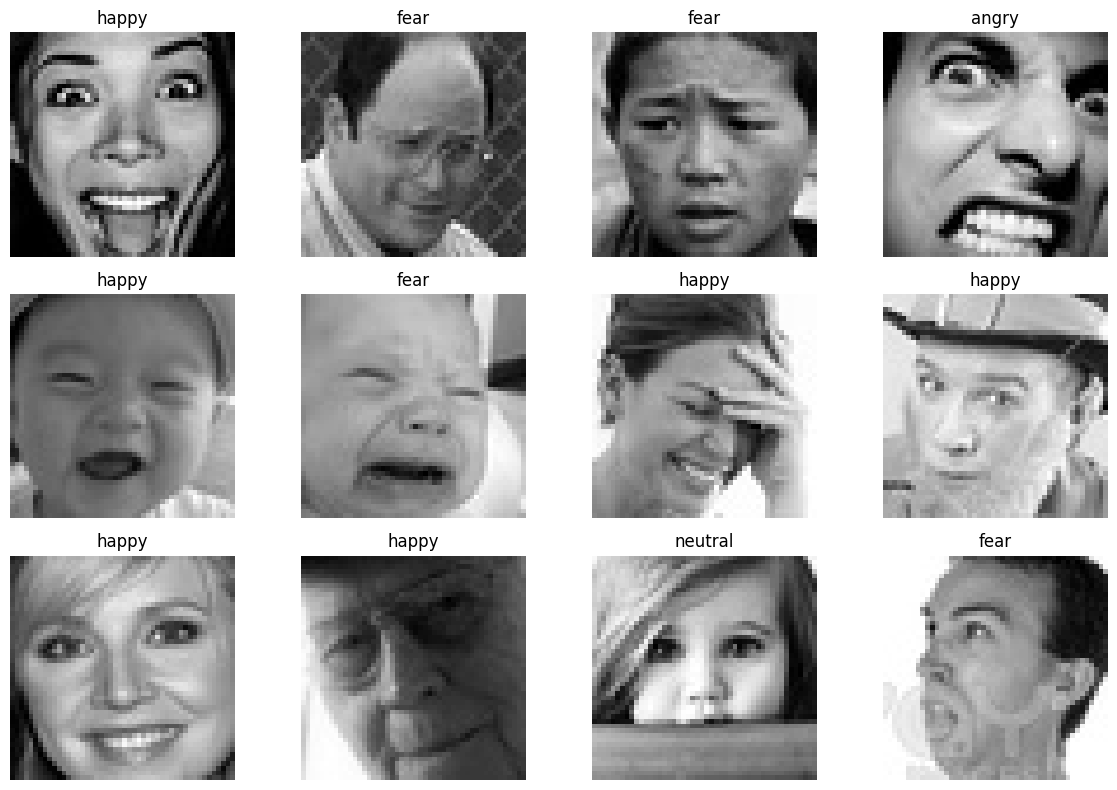

In [ ]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(tf.squeeze(images[i]), cmap="gray")
        plt.title(EXPECTED_CLASSES[int(labels[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

### 2.2 Calculate class weights

The disgust class is much smaller than happy. Class weights penalize mistakes on under-represented classes more strongly. This is one mitigation, not a guarantee of balanced performance; per-class metrics will still be inspected.

In [ ]:
phase2_train_counts = {
    "angry": 3774, "disgust": 366, "fear": 3842,
    "happy": 7035, "neutral": 4837, "sad": 4729, "surprise": 2598
}
total_train = sum(phase2_train_counts.values())
num_classes = len(EXPECTED_CLASSES)

class_weight = {
    i: total_train / (num_classes * phase2_train_counts[name])
    for i, name in enumerate(EXPECTED_CLASSES)
}
print("Class weights:")
for i, name in enumerate(EXPECTED_CLASSES):
    print(f"{name:10s}: {class_weight[i]:.3f}")

Class weights:
angry     : 1.029
disgust   : 10.609
fear      : 1.011
happy     : 0.552
neutral   : 0.803
sad       : 0.821
surprise  : 1.495


## 3. Common callbacks and plotting helpers

Early stopping restores the best validation-loss weights. ReduceLROnPlateau lowers the learning rate when validation loss stops improving. ModelCheckpoint saves the best validation checkpoint.

In [ ]:
OUTPUT_DIR = "/content/DeepFER_Phase3_Outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def make_callbacks(model_name):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            os.path.join(OUTPUT_DIR, f"{model_name}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3,
            patience=3, min_lr=1e-6, verbose=1
        )
    ]

def plot_history(history, title, filename):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["accuracy"], label="train")
    axes[0].plot(hist["val_accuracy"], label="validation")
    axes[0].set_title("Accuracy"); axes[0].legend()
    axes[1].plot(hist["loss"], label="train")
    axes[1].plot(hist["val_loss"], label="validation")
    axes[1].set_title("Loss"); axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, filename), dpi=150)
    plt.show()

## 4. Model A — Custom CNN

The CNN learns image features through convolution and pooling. Batch normalization helps stabilize training; dropout reduces overfitting. Augmentation is applied only to training images.

In [ ]:
cnn_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomContrast(0.10)
], name="cnn_augmentation")

def build_custom_cnn():
    inputs = tf.keras.Input(shape=(48, 48, 1))
    x = tf.keras.layers.Rescaling(1./255)(inputs)
    x = cnn_augmentation(x)

    for filters in [32, 64, 128]:
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(0.20)(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.40)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="DeepFER_CustomCNN")

cnn_model = build_custom_cnn()
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_model.summary()

Model: "DeepFER_CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_augmentation (Sequential)   │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 322,599 (1.23 MB)

 Trainable params: 321,703 (1.23 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/15
425/425 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1543 - loss: 2.0009
Epoch 1: val_loss improved from None to 1.91781, saving model to /content/DeepFER_Phase3_Outputs/custom_cnn_best.keras

Epoch 1: finished saving model to /content/DeepFER_Phase3_Outputs/custom_cnn_best.keras
425/425 ━━━━━━━━━━━━━━━━━━━━ 535s 1s/step - accuracy: 0.1581 - loss: 1.9434 - val_accuracy: 0.1583 - val_loss: 1.9178 - learning_rate: 0.0010
Epoch 2/15
425/425 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1819 - loss: 1.8878
Epoch 2: val_loss improved from 1.91781 to 1.90991, saving model to /content/DeepFER_Phase3_Outputs/custom_cnn_best.keras

Epoch 2: finished saving model to /content/DeepFER_Phase3_Outputs/custom_cnn_best.keras
425/425 ━━━━━━━━━━━━━━━━━━━━ 524s 1s/step - accuracy: 0.1843 - loss: 1.8742 - val_accuracy: 0.1854 - val_loss: 1.9099 - learning_rate: 0.0010
Epoch 3/15
425/425 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2115 - loss: 1.8210
Epoch 3: val_loss improved from 1.90991 to

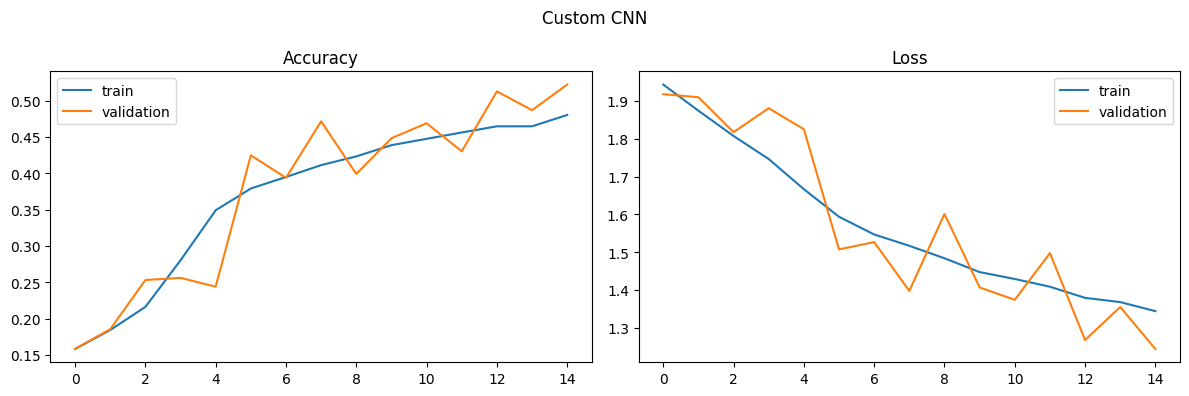

In [ ]:
EPOCHS_CNN = 15  # Early stopping may stop sooner
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    class_weight=class_weight,
    callbacks=make_callbacks("custom_cnn")
)
plot_history(cnn_history, "Custom CNN", "custom_cnn_training_curves.png")

## 5. Model B — Transfer learning with MobileNetV2

MobileNetV2 expects three-channel inputs. We convert each grayscale image to RGB and resize it to 96×96. The model rescales pixel values to [-1, 1], as expected by MobileNetV2 preprocessing.

**Stage 1:** freeze the ImageNet backbone and train the classification head.  
**Stage 2:** unfreeze only the later backbone layers and fine-tune with a very small learning rate.

If Colab runs out of memory, reduce `BATCH_SIZE_TL` to 32 or 16 and rerun this section.

In [ ]:
TL_SIZE = (96, 96)
BATCH_SIZE_TL = 32

def prepare_for_mobilenet(images, labels):
    images = tf.image.grayscale_to_rgb(images)
    images = tf.image.resize(images, TL_SIZE)
    return images, labels

train_tl = train_ds.map(prepare_for_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_tl = val_ds.map(prepare_for_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_tl = test_ds.map(prepare_for_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Rebatch the transfer-learning datasets to reduce memory use.
train_tl = train_tl.unbatch().batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)
val_tl = val_tl.unbatch().batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)
test_tl = test_tl.unbatch().batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(96, 96, 3))
x = tf.keras.layers.Rescaling(scale=1./127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.35)(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

tl_model = tf.keras.Model(inputs, outputs, name="DeepFER_MobileNetV2")
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DeepFER_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
EPOCHS_HEAD = 15
tl_head_history = tl_model.fit(
    train_tl,
    validation_data=val_tl,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=make_callbacks("mobilenetv2_head")
)

Epoch 1/15
    850/Unknown 177s 202ms/step - accuracy: 0.2662 - loss: 2.1209

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 1.51149, saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_head_best.keras

Epoch 1: finished saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_head_best.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 201s 230ms/step - accuracy: 0.3091 - loss: 1.9234 - val_accuracy: 0.4314 - val_loss: 1.5115 - learning_rate: 0.0010
Epoch 2/15
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3720 - loss: 1.6716
Epoch 2: val_loss improved from 1.51149 to 1.48504, saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_head_best.keras

Epoch 2: finished saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_head_best.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 202s 237ms/step - accuracy: 0.3700 - loss: 1.6539 - val_accuracy: 0.4288 - val_loss: 1.4850 - learning_rate: 0.0010
Epoch 3/15
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3845 - loss: 1.6260
Epoch 3: val_loss improved from 1.48504 to 1.44417, saving model to /content/DeepFER_Phase

### 5.1 Fine-tune the last MobileNetV2 layers

Keep most of the backbone frozen. Batch-normalization layers remain frozen to reduce instability on this comparatively small dataset.

Epoch 1/15
    850/Unknown 270s 306ms/step - accuracy: 0.4130 - loss: 1.4972
Epoch 1: val_loss improved from None to 1.43477, saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_finetuned_best.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 295s 336ms/step - accuracy: 0.4217 - loss: 1.4751 - val_accuracy: 0.4588 - val_loss: 1.4348 - learning_rate: 1.0000e-05
Epoch 2/15
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.4547 - loss: 1.3895
Epoch 2: val_loss improved from 1.43477 to 1.35541, saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /content/DeepFER_Phase3_Outputs/mobilenetv2_finetuned_best.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 319s 376ms/step - accuracy: 0.4602 - loss: 1.3639 - val_accuracy: 0.4820 - val_loss: 1.3554 - learning_rate: 1.0000e-05
Epoch 3/15
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.4776 -

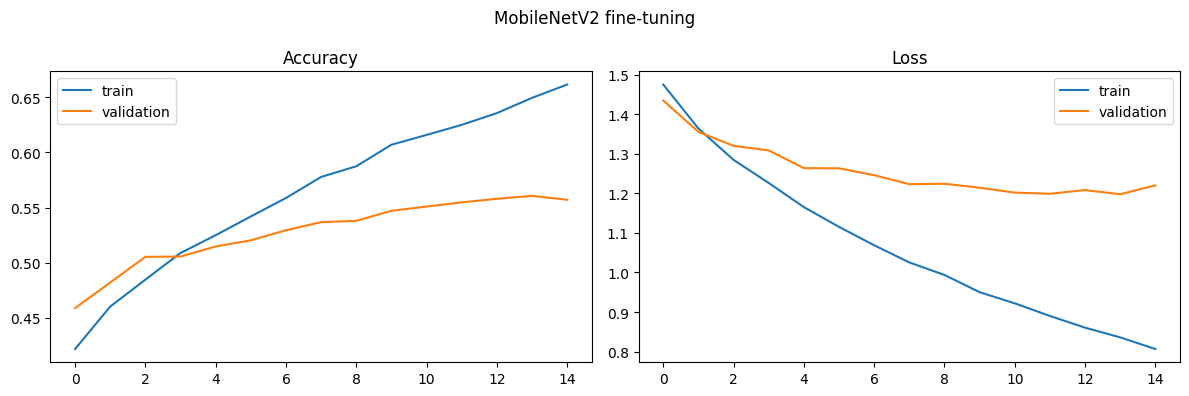

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS_FINE = 15
tl_fine_history = tl_model.fit(
    train_tl,
    validation_data=val_tl,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=make_callbacks("mobilenetv2_finetuned")
)
plot_history(tl_fine_history, "MobileNetV2 fine-tuning", "mobilenetv2_training_curves.png")

## 6. Compare models using validation data only

Choose the model using validation macro F1-score, not the held-out test set. Macro F1 gives each emotion equal weight, which is important when class counts differ.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for x, y in dataset:
        probs = model.predict(x, verbose=0)
        y_true.extend(y.numpy().tolist())
        y_prob.extend(probs.tolist())
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    return y_true, np.argmax(y_prob, axis=1), y_prob

cnn_val_true, cnn_val_pred, _ = collect_predictions(cnn_model, val_ds)
tl_val_true, tl_val_pred, _ = collect_predictions(tl_model, val_tl)

validation_results = pd.DataFrame([
    {
        "model": "Custom CNN",
        "accuracy": accuracy_score(cnn_val_true, cnn_val_pred),
        "macro_f1": f1_score(cnn_val_true, cnn_val_pred, average="macro")
    },
    {
        "model": "MobileNetV2 fine-tuned",
        "accuracy": accuracy_score(tl_val_true, tl_val_pred),
        "macro_f1": f1_score(tl_val_true, tl_val_pred, average="macro")
    }
]).sort_values("macro_f1", ascending=False)

display(validation_results)
validation_results.to_csv(os.path.join(OUTPUT_DIR, "validation_model_comparison.csv"), index=False)

best_model_name = validation_results.iloc[0]["model"]
best_model = cnn_model if best_model_name == "Custom CNN" else tl_model
best_input_ds = val_ds if best_model_name == "Custom CNN" else val_tl
print("Selected using validation macro F1:", best_model_name)

,model,accuracy,macro_f1
0,Custom CNN,0.522072,0.448665
1,MobileNetV2 fine-tuned,0.454679,0.402132


Selected using validation macro F1: Custom CNN


## 7. Final evaluation on the held-out test set

Run this section only after model selection is complete. Do not change architecture or hyperparameters based on test results; doing so would turn the test set into another validation set.

Selected model: Custom CNN
Test accuracy: 0.5291
Test macro F1: 0.4536


,precision,recall,f1-score,support
angry,0.545000,0.230932,0.324405,472.000000
disgust,0.160839,0.500000,0.243386,46.000000
fear,0.343478,0.164583,0.222535,480.000000
happy,0.694184,0.841866,0.760925,879.000000
neutral,0.478395,0.512397,0.494812,605.000000
sad,0.403983,0.480541,0.438949,591.000000
surprise,0.620098,0.778462,0.690314,325.000000
accuracy,0.529135,0.529135,0.529135,0.529135
macro avg,0.463711,0.501254,0.453618,3398.000000
weighted avg,0.520721,0.529135,0.507098,3398.000000


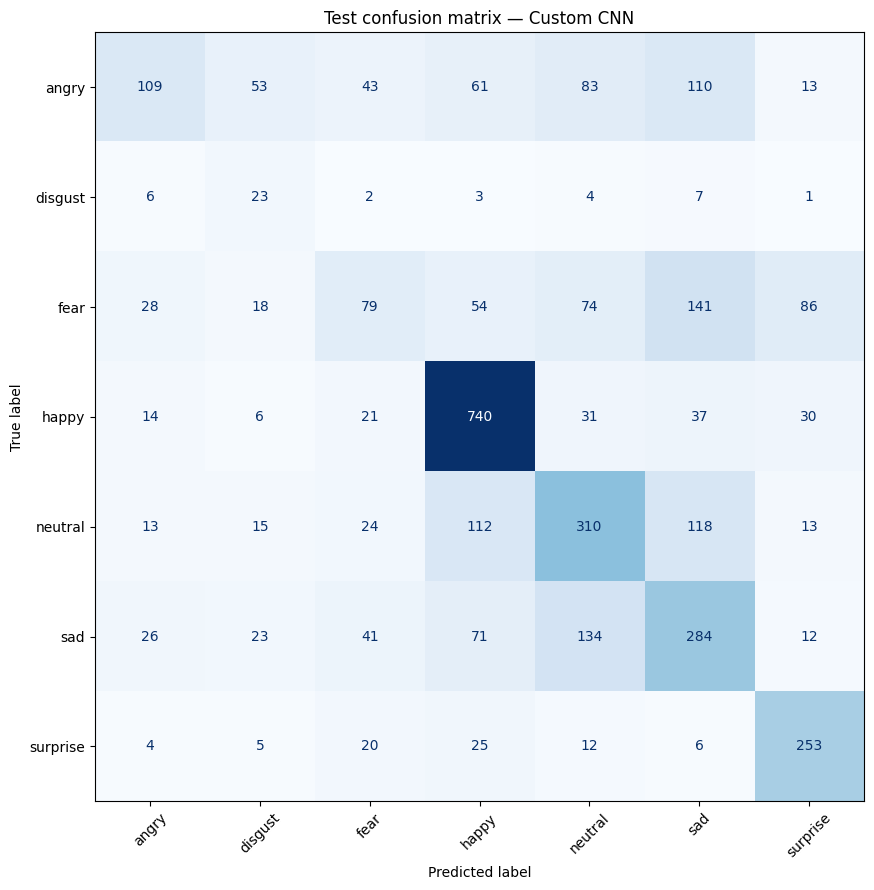

In [ ]:
test_input_ds = test_ds if best_model_name == "Custom CNN" else test_tl
y_test, y_pred, y_prob = collect_predictions(best_model, test_input_ds)

test_accuracy = accuracy_score(y_test, y_pred)
test_macro_f1 = f1_score(y_test, y_pred, average="macro")
report_dict = classification_report(
    y_test, y_pred, target_names=EXPECTED_CLASSES,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()

print(f"Selected model: {best_model_name}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro F1: {test_macro_f1:.4f}")
display(report_df)
report_df.to_csv(os.path.join(OUTPUT_DIR, "test_classification_report.csv"))

cm = confusion_matrix(y_test, y_pred, labels=list(range(num_classes)))
disp = ConfusionMatrixDisplay(cm, display_labels=EXPECTED_CLASSES)
fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"Test confusion matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "test_confusion_matrix.png"), dpi=160)
plt.show()

## 8. Save the selected model and metadata

For the CNN, the saved model accepts 48×48 grayscale images. For MobileNetV2, it accepts 96×96 RGB images. Phase 4 will use the metadata to apply the correct preprocessing before prediction.

In [ ]:
MODEL_PATH = os.path.join(OUTPUT_DIR, "deepfer_best_model.keras")
best_model.save(MODEL_PATH)

metadata = {
    "project": "DeepFER",
    "selected_model": best_model_name,
    "class_names": EXPECTED_CLASSES,
    "input_shape": [48, 48, 1] if best_model_name == "Custom CNN" else [96, 96, 3],
    "input_color_mode": "grayscale" if best_model_name == "Custom CNN" else "rgb",
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "seed": SEED,
    "note": "Predicts visible facial-expression categories, not a person's internal emotional state."
}
with open(os.path.join(OUTPUT_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", MODEL_PATH)
print(json.dumps(metadata, indent=2))

Saved: /content/DeepFER_Phase3_Outputs/deepfer_best_model.keras
{
  "project": "DeepFER",
  "selected_model": "Custom CNN",
  "class_names": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
  ],
  "input_shape": [
    48,
    48,
    1
  ],
  "input_color_mode": "grayscale",
  "test_accuracy": 0.5291347851677457,
  "test_macro_f1": 0.45361812727192197,
  "seed": 42,
  "note": "Predicts visible facial-expression categories, not a person's internal emotional state."
}


## 9. Download Phase 3 outputs

The ZIP includes the selected model, metadata, validation comparison, test report and plots. Keep the full notebook too, so your training process is reproducible.

In [ ]:
phase3_zip = "/content/DeepFER_Phase3_Outputs.zip"
if os.path.exists(phase3_zip):
    os.remove(phase3_zip)

shutil.make_archive(
    "/content/DeepFER_Phase3_Outputs",
    "zip",
    OUTPUT_DIR
)

from google.colab import files
files.download(phase3_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Phase 3 completion checklist

- [ ] Dataset paths and seven classes validated.
- [ ] Sample images inspected.
- [ ] Class weights calculated.
- [ ] Custom CNN trained and best checkpoint saved.
- [ ] MobileNetV2 head trained and fine-tuned.
- [ ] Models compared using validation macro F1.
- [ ] One model selected before test evaluation.
- [ ] Test accuracy, macro F1, classification report and confusion matrix saved.
- [ ] `deepfer_best_model.keras` and `model_metadata.json` downloaded.

### What to share when finished
Upload `DeepFER_Phase3_Outputs.zip` and share:
- Which model was selected?
- Validation accuracy and macro F1 for both models.
- Final test accuracy and macro F1.
- Any Colab errors or warnings.

We will review the metrics before moving to Phase 4 (Streamlit inference app, image upload/webcam flow, Dockerfile and deployment documentation).